# Pipeline B (newcomer): interest-rate regression from probability of default

| Setting | Known when deciding | PD model | Rate model |
|---|---|---|---|
| Reference: already-priced loan | rate + grade | notebooks 02–05 | none (rate already set) |
| Pipeline A: graded applicant | grade only | notebook 08 | notebook 09 |
| **Pipeline B: newcomer** | **neither** | notebook 06 | **this notebook** |

**Research question 2:** what interest rate should an applicant be given?

**Idea (risk-based pricing).** Past loans show how lenders priced risk. We learn

$$\text{rate} = f(\text{PD},\ \text{applicant details})$$

where **PD** is the **applicant-only, calibrated, out-of-fold** probability of default from notebook 06 (the Random Forest that never sees the rate or grade). Because each PD came from a model that did not train on that applicant, it behaves like a real newcomer's PD.

| Used as input | Not used | Why not |
|---|---|---|
| PD (notebook 06), age, income, employment length, home ownership, loan intent, loan amount, loan-to-income, past default, credit-history length | `loan_grade` | the lender's pricing bucket, set together with the rate (near-leakage) and not available for a newcomer |
| | `loan_status` | the future outcome |

**Data:** training applicants (80% split) with a known rate. **Target:** `loan_int_rate` (%). Rows without a recorded rate are left out (nothing to learn from).

**Models (from the proposal):** Linear regression (baseline), Ridge, Lasso, Random Forest regressor. **Added to try to improve R²:** a gradient boosting regressor and a two-stage *predict-the-grade-first* approach (Step 2b). **Validation:** 5-fold CV on the training set. **Metrics:** RMSE (error in percentage points), R², MAE. The test set stays locked.

**Use:** only applicants whose PD is below the notebook-06 cutoff are approved and get a rate; the rest are declined.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.model_selection import KFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.inspection import partial_dependence

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, DATA, REPORTS, APPLICANT_NUM_COLS, APPLICANT_CAT_COLS,
                        load_train, make_pipeline)

X_train, y_default = load_train()
pd_file = pd.read_csv(DATA / "oof_pd_applicant.csv")          # same row order as train.csv
pd_choice = json.loads((REPORTS / "applicant_pd_choice.json").read_text())
assert len(pd_file) == len(X_train)

data = X_train.copy()
data["applicant_pd"] = pd_file["applicant_pd"].values
data = data[data["loan_int_rate"].notna()].reset_index(drop=True)
y_rate = data["loan_int_rate"]
PD_CUT = pd_choice["pd_cutoff"]
approved = (data["applicant_pd"] < PD_CUT).to_numpy()

print(f"training loans with a known rate: {len(data):,} (of {len(X_train):,})")
print(f"PD model: {pd_choice['model']} [{pd_choice['calibration']}], PD cutoff {PD_CUT:.3f} -> "
      f"{approved.mean():.1%} would be approved")
print(f"rate: mean {y_rate.mean():.2f}%, sd {y_rate.std():.2f}, range {y_rate.min():.2f}-{y_rate.max():.2f}%")

# Three input sets
FEATURES = {
    "PD only": (["applicant_pd"], []),
    "details only (no PD)": (APPLICANT_NUM_COLS, APPLICANT_CAT_COLS),
    "PD + details": (["applicant_pd"] + APPLICANT_NUM_COLS, APPLICANT_CAT_COLS),
}
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

def pipe(model, feats):
    num, cat = FEATURES[feats]
    return make_pipeline(model, num_cols=num, cat_cols=cat)

def cv_scores(model, feats):
    r = cross_validate(pipe(model, feats), data, y_rate, cv=kf, scoring=SCORING, n_jobs=5)
    return {"RMSE": -r["test_RMSE"].mean(), "RMSE sd": r["test_RMSE"].std(),
            "MAE": -r["test_MAE"].mean(), "R2": r["test_R2"].mean()}

training loans with a known rate: 23,464 (of 25,927)
PD model: Random Forest [Platt (sigmoid)], PD cutoff 0.388 -> 84.1% would be approved
rate: mean 11.03%, sd 3.24, range 5.42-23.22%


## Step 1: Tune Ridge, Lasso and the Random Forest regressor

- **Ridge** minimises $\sum (y_i - \hat y_i)^2 + \alpha \sum_j w_j^2$: shrinks all coefficients, which stabilises correlated inputs (income, loan amount, loan-to-income).
- **Lasso** minimises $\sum (y_i - \hat y_i)^2 + \alpha \sum_j |w_j|$: can set coefficients to exactly 0, i.e. drops inputs.
- **Random Forest regressor:** averages 300 regression trees (non-linear, captures interactions).
- **Gradient boosting regressor** (`HistGradientBoostingRegressor`, added to try to improve R²): builds small trees **one after another**, each correcting the errors of the trees before it; usually the strongest model on tabular data. Tuned with a 12-combination randomized search (learning rate, number of trees, leaf count, leaf size, L2 penalty).

α for Ridge and Lasso is chosen by 5-fold CV (lowest mean RMSE) on the **PD + details** inputs; the forest gets a small randomized search (10 combinations). The chosen settings are then used for every input set.

Ridge: best alpha = 10 (CV RMSE 2.7355)
Lasso: best alpha = 0.002154 (CV RMSE 2.7355)


Random Forest regressor: best {'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10} (CV RMSE 2.7022)


Gradient boosting regressor: best {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0} (CV RMSE 2.7062)
[131s]


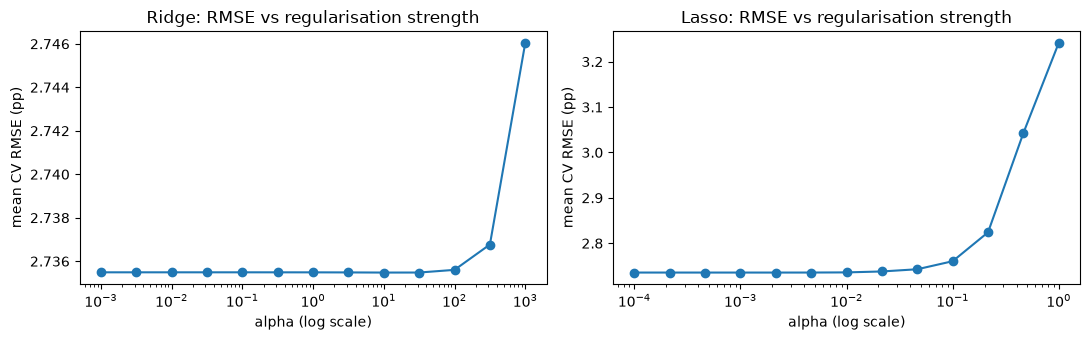

In [2]:
start = time.time()
ridge_gs = GridSearchCV(pipe(Ridge(), "PD + details"), {"model__alpha": np.logspace(-3, 3, 13)},
                        cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(data, y_rate)
lasso_gs = GridSearchCV(pipe(Lasso(max_iter=20000), "PD + details"), {"model__alpha": np.logspace(-4, 0, 13)},
                        cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(data, y_rate)
RIDGE_A, LASSO_A = ridge_gs.best_params_["model__alpha"], lasso_gs.best_params_["model__alpha"]
print(f"Ridge: best alpha = {RIDGE_A:.4g} (CV RMSE {-ridge_gs.best_score_:.4f})")
print(f"Lasso: best alpha = {LASSO_A:.4g} (CV RMSE {-lasso_gs.best_score_:.4f})")

rf_rs = RandomizedSearchCV(pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
                                "PD + details"),
                           {"model__max_depth": [None, 10, 15, 20], "model__min_samples_leaf": [1, 5, 10, 20],
                            "model__max_features": ["sqrt", 0.5, None]},
                           n_iter=10, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1,
                           random_state=RANDOM_STATE).fit(data, y_rate)
RF_P = {k.replace("model__", ""): v for k, v in rf_rs.best_params_.items()}
print(f"Random Forest regressor: best {RF_P} (CV RMSE {-rf_rs.best_score_:.4f})")
hgb_rs = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE), "PD + details"),
                            {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [200, 400, 800],
                             "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [20, 50, 100],
                             "model__l2_regularization": [0.0, 1.0]},
                            n_iter=12, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1,
                            random_state=RANDOM_STATE).fit(data, y_rate)
HGB_P = {k.replace("model__", ""): v for k, v in hgb_rs.best_params_.items()}
print(f"Gradient boosting regressor: best {HGB_P} (CV RMSE {-hgb_rs.best_score_:.4f})")
print(f"[{time.time() - start:.0f}s]")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, gs) in zip(axes, [("Ridge", ridge_gs), ("Lasso", lasso_gs)]):
    res = pd.DataFrame(gs.cv_results_)
    ax.plot(res["param_model__alpha"].astype(float), -res["mean_test_score"], marker="o")
    ax.set_xscale("log"); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("mean CV RMSE (pp)")
    ax.set_title(f"{name}: RMSE vs regularisation strength")
plt.tight_layout(); plt.show()

## Step 2: Validation scores of every model and input set

5-fold CV (same folds for every row of the table). A **"predict the average rate"** model is included as the floor: any useful model must beat its RMSE (R² = 0).

In [3]:
MODELS = {
    "Mean rate (no model)": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    f"Ridge (alpha={RIDGE_A:.3g})": Ridge(alpha=RIDGE_A),
    f"Lasso (alpha={LASSO_A:.3g})": Lasso(alpha=LASSO_A, max_iter=20000),
    "Random Forest regressor": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **RF_P),
    "Gradient boosting regressor": HistGradientBoostingRegressor(random_state=RANDOM_STATE, **HGB_P),
}
rows = []
for feats in FEATURES:
    for name, model in MODELS.items():
        if name.startswith("Mean") and feats != "PD + details":
            continue
        t0 = time.time()
        rows.append({"inputs": feats, "model": name, **cv_scores(model, feats), "seconds": round(time.time() - t0)})
results = pd.DataFrame(rows).set_index(["inputs", "model"])
display(results.round(4))

# Reference only (NOT usable for a newcomer): how much of pricing the lender's grade explains
ref = cross_validate(make_pipeline(LinearRegression(), num_cols=["applicant_pd"] + APPLICANT_NUM_COLS,
                                   cat_cols=APPLICANT_CAT_COLS + ["loan_grade"]),
                     data, y_rate, cv=kf, scoring=SCORING)
print(f"Reference: linear regression WITH loan_grade (not usable for newcomers): "
      f"RMSE {-ref['test_RMSE'].mean():.3f}, R2 {ref['test_R2'].mean():.3f}")

RMSE  RMSE sd     MAE  \
inputs               model                                                  
PD only              Linear regression            3.1666   0.0254  2.6337   
                     Ridge (alpha=10)             3.1666   0.0254  2.6338   
                     Lasso (alpha=0.00215)        3.1666   0.0253  2.6338   
                     Random Forest regressor      3.0976   0.0258  2.5544   
                     Gradient boosting regressor  3.0880   0.0266  2.5488   
details only (no PD) Linear regression            2.7429   0.0303  2.2009   
                     Ridge (alpha=10)             2.7429   0.0302  2.2008   
                     Lasso (alpha=0.00215)        2.7430   0.0300  2.2009   
                     Random Forest regressor      2.7114   0.0316  2.1721   
                     Gradient boosting regressor  2.7134   0.0308  2.1742   
PD + details         Mean rate (no model)         3.2415   0.0148  2.6941   
                     Linear regression            2.7355   0.0331  2.1982   
                     Ridge (alpha=10)             2.7355   0.0330  2.1981   
                     Lasso (alpha=0.00215)        2.7355   0.0328  2.1980   
                     Random Forest regressor      2.7022   0.0318  2.1672   
                     Gradient boosting regressor  2.7062   0.0323  2.1700   

                                                      R2  seconds  
inputs               model                                         
PD only              Linear regression            0.0455        9  
                     Ridge (alpha=10)             0.0455        0  
                     Lasso (alpha=0.00215)        0.0455        0  
                     Random Forest regressor      0.0867        6  
                     Gradient boosting regressor  0.0923        1  
details only (no PD) Linear regression            0.2838        0  
                     Ridge (alpha=10)             0.2838        0  
                     Lasso (alpha=0.00215)        0.2838        1  
                     Random Forest regressor      0.3002        5  
                     Gradient boosting regressor  0.2991        2  
PD + details         Mean rate (no model)        -0.0002        0  
                     Linear regression            0.2877        0  
                     Ridge (alpha=10)             0.2877        0  
                     Lasso (alpha=0.00215)        0.2877        0  
                     Random Forest regressor      0.3049        7  
                     Gradient boosting regressor  0.3028        2

Reference: linear regression WITH loan_grade (not usable for newcomers): RMSE 1.008, R2 0.903


## Step 2b: Two-stage approach (predict the grade first, then the rate)

A lender prices in two steps: **assign a grade, then set the rate from the grade** (with the grade, R² ≈ 0.90, notebook 09). A newcomer has no grade, so here we **predict** it:

1. **Stage 1 (classification):** a Random Forest classifier predicts the lender's grade (A–G) from the applicant's details + PD, giving a **probability for each grade**.
2. **Stage 2 (regression):** the rate models get those 7 grade probabilities as extra inputs.

**Leak-free:** the grade probabilities are **out-of-fold** (`cross_val_predict`, same 5 folds): each applicant's predicted grade comes from a stage-1 model that did not see that applicant. (A fully nested version would also refit stage 1 inside every stage-2 training fold; out-of-fold stacking is the standard close approximation.)

Stage 1 only sees the same applicant details, so it adds **structure, not new information**: a large gain would be surprising.

In [4]:
start = time.time()
GRADES = sorted(data["loan_grade"].unique())
stage1 = make_pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
                       num_cols=["applicant_pd"] + APPLICANT_NUM_COLS, cat_cols=APPLICANT_CAT_COLS)
grade_proba = cross_val_predict(stage1, data, data["loan_grade"], cv=kf, method="predict_proba")
PCOLS = [f"p_grade_{g}" for g in GRADES]
for j, c in enumerate(PCOLS):
    data[c] = grade_proba[:, j]
pred_grade = np.array(GRADES)[grade_proba.argmax(axis=1)]
true_i = data["loan_grade"].map({g: i for i, g in enumerate(GRADES)}).to_numpy()
pred_i = grade_proba.argmax(axis=1)
print(f"Stage 1 (grade classifier, out-of-fold): exact grade correct {np.mean(pred_i == true_i):.3f}, "
      f"within one grade {np.mean(np.abs(pred_i - true_i) <= 1):.3f}  [{time.time() - start:.0f}s]")
print("Rows = true grade, columns = predicted grade (share of each true grade):")
display(pd.crosstab(data["loan_grade"], pd.Series(pred_grade, name="predicted"), normalize="index").round(2))

# Stage 2: rate models with the grade probabilities as extra inputs
FEATURES["PD + details + predicted grade"] = (["applicant_pd"] + APPLICANT_NUM_COLS + PCOLS, APPLICANT_CAT_COLS)
new = [{"inputs": "PD + details + predicted grade", "model": name, **cv_scores(MODELS[name], "PD + details + predicted grade")}
       for name in ["Linear regression", "Random Forest regressor", "Gradient boosting regressor"]]
results = pd.concat([results, pd.DataFrame(new).set_index(["inputs", "model"])])
print(f"[{time.time() - start:.0f}s]  All results (sorted by RMSE):")
display(results.sort_values("RMSE").round(4))

Stage 1 (grade classifier, out-of-fold): exact grade correct 0.493, within one grade 0.863  [16s]
Rows = true grade, columns = predicted grade (share of each true grade):


predicted,A,B,C,D
loan_grade,,,,
A,0.64,0.36,0.00,0.00
B,0.45,0.55,0.00,0.00
C,0.23,0.26,0.47,0.04
D,0.20,0.29,0.41,0.11
E,0.15,0.37,0.38,0.10
F,0.18,0.37,0.29,0.16
G,0.10,0.33,0.31,0.25


[29s]  All results (sorted by RMSE):


RMSE  RMSE sd  \
inputs                         model                                          
PD + details                   Random Forest regressor      2.7022   0.0318   
PD + details + predicted grade Random Forest regressor      2.7054   0.0309   
PD + details                   Gradient boosting regressor  2.7062   0.0323   
PD + details + predicted grade Linear regression            2.7087   0.0322   
                               Gradient boosting regressor  2.7095   0.0302   
details only (no PD)           Random Forest regressor      2.7114   0.0316   
                               Gradient boosting regressor  2.7134   0.0308   
PD + details                   Lasso (alpha=0.00215)        2.7355   0.0328   
                               Ridge (alpha=10)             2.7355   0.0330   
                               Linear regression            2.7355   0.0331   
details only (no PD)           Ridge (alpha=10)             2.7429   0.0302   
                               Linear regression            2.7429   0.0303   
                               Lasso (alpha=0.00215)        2.7430   0.0300   
PD only                        Gradient boosting regressor  3.0880   0.0266   
                               Random Forest regressor      3.0976   0.0258   
                               Ridge (alpha=10)             3.1666   0.0254   
                               Linear regression            3.1666   0.0254   
                               Lasso (alpha=0.00215)        3.1666   0.0253   
PD + details                   Mean rate (no model)         3.2415   0.0148   

                                                               MAE      R2  \
inputs                         model                                         
PD + details                   Random Forest regressor      2.1672  0.3049   
PD + details + predicted grade Random Forest regressor      2.1699  0.3032   
PD + details                   Gradient boosting regressor  2.1700  0.3028   
PD + details + predicted grade Linear regression            2.1712  0.3016   
                               Gradient boosting regressor  2.1719  0.3012   
details only (no PD)           Random Forest regressor      2.1721  0.3002   
                               Gradient boosting regressor  2.1742  0.2991   
PD + details                   Lasso (alpha=0.00215)        2.1980  0.2877   
                               Ridge (alpha=10)             2.1981  0.2877   
                               Linear regression            2.1982  0.2877   
details only (no PD)           Ridge (alpha=10)             2.2008  0.2838   
                               Linear regression            2.2009  0.2838   
                               Lasso (alpha=0.00215)        2.2009  0.2838   
PD only                        Gradient boosting regressor  2.5488  0.0923   
                               Random Forest regressor      2.5544  0.0867   
                               Ridge (alpha=10)             2.6338  0.0455   
                               Linear regression            2.6337  0.0455   
                               Lasso (alpha=0.00215)        2.6338  0.0455   
PD + details                   Mean rate (no model)         2.6941 -0.0002   

                                                            seconds  
inputs                         model                                 
PD + details                   Random Forest regressor          7.0  
PD + details + predicted grade Random Forest regressor          NaN  
PD + details                   Gradient boosting regressor      2.0  
PD + details + predicted grade Linear regression                NaN  
                               Gradient boosting regressor      NaN  
details only (no PD)           Random Forest regressor          5.0  
                               Gradient boosting regressor      2.0  
PD + details                   Lasso (alpha=0.00215)            0.0  
                               Ridge (alpha=10)                

## Step 3: Choose the rate model and check it

**Choice:** the model + input set with the lowest mean CV RMSE.

**Checks** on the chosen model's **out-of-fold** predictions:
1. predicted vs actual rate, and the error for **approved** applicants (PD below the cutoff), the only ones who get a rate;
2. **does the rate rise with PD?** Partial dependence: change only the PD, keep each applicant's other details, and average the predicted rate;
3. for the linear models, the coefficients (which inputs Lasso keeps, and the sign of PD).

chosen rate model: Random Forest regressor on 'PD + details' inputs (CV RMSE 2.702 pp, R2 0.305)


  all loans                  n=23,464  RMSE 2.702 pp   MAE 2.167 pp
  approved (PD < cutoff)     n=19,740  RMSE 2.713 pp   MAE 2.188 pp
  declined (PD >= cutoff)    n= 3,724  RMSE 2.644 pp   MAE 2.055 pp



predicted rate at PD 0.005: 10.90%   at PD 0.388: 11.53%   (monotone increasing: False)


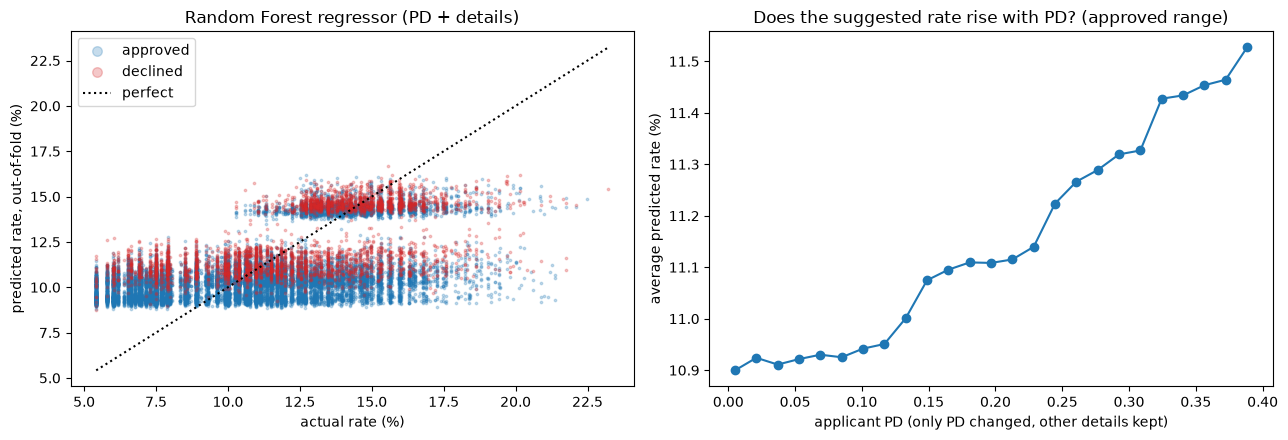


Linear-model coefficients (pp of rate per 1 SD of a numeric input, or for a category vs the rest):


,Linear regression,Ridge (alpha=10),Lasso (alpha=0.00215)
applicant_pd,0.276,0.276,0.272
person_age,-0.068,-0.067,-0.050
person_income,-0.114,-0.113,-0.104
person_emp_length,-0.094,-0.094,-0.093
loan_amnt,0.596,0.595,0.582
loan_percent_income,-0.229,-0.229,-0.214
cb_person_cred_hist_length,0.082,0.082,0.064
person_home_ownership_MORTGAGE,-0.557,-0.543,-0.512
person_home_ownership_OTHER,0.447,0.407,0.000
person_home_ownership_OWN,-0.056,-0.043,-0.000


inputs Lasso dropped (coefficient exactly 0): ['person_home_ownership_OTHER', 'person_home_ownership_OWN', 'loan_intent_EDUCATION']


In [5]:
best_inputs, best_model = results["RMSE"].drop(index="Mean rate (no model)", level="model").idxmin()
TWO_STAGE = best_inputs == "PD + details + predicted grade"
print(f"chosen rate model: {best_model} on '{best_inputs}' inputs "
      f"(CV RMSE {results.loc[(best_inputs, best_model), 'RMSE']:.3f} pp, R2 {results.loc[(best_inputs, best_model), 'R2']:.3f})")
rate_pipe = pipe(MODELS[best_model], best_inputs)
oof_rate = cross_val_predict(rate_pipe, data, y_rate, cv=kf, n_jobs=5)
err = oof_rate - y_rate
for label, m in [("all loans", np.ones(len(data), bool)), ("approved (PD < cutoff)", approved),
                 ("declined (PD >= cutoff)", ~approved)]:
    print(f"  {label:<26} n={m.sum():>6,}  RMSE {np.sqrt(np.mean(err[m] ** 2)):.3f} pp   MAE {np.mean(np.abs(err[m])):.3f} pp")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.scatter(y_rate[approved], oof_rate[approved], s=3, alpha=0.25, label="approved")
ax.scatter(y_rate[~approved], oof_rate[~approved], s=3, alpha=0.25, color="tab:red", label="declined")
lims = [y_rate.min(), y_rate.max()]
ax.plot(lims, lims, color="black", linestyle=":", label="perfect")
ax.set_xlabel("actual rate (%)"); ax.set_ylabel("predicted rate, out-of-fold (%)")
ax.set_title(f"{best_model} ({best_inputs})"); ax.legend(markerscale=4)

ax = axes[1]
if "PD" in best_inputs and not best_inputs.startswith("details"):
    fitted = rate_pipe.fit(data, y_rate)
    grid = np.linspace(0.005, PD_CUT, 25)
    pdep = [fitted.predict(data.assign(applicant_pd=g)).mean() for g in grid]
    ax.plot(grid, pdep, marker="o")
    ax.set_xlabel("applicant PD (only PD changed, other details kept)"); ax.set_ylabel("average predicted rate (%)")
    ax.set_title("Does the suggested rate rise with PD? (approved range)")
    print(f"\npredicted rate at PD {grid[0]:.3f}: {pdep[0]:.2f}%   at PD {grid[-1]:.3f}: {pdep[-1]:.2f}%   "
          f"(monotone increasing: {bool(np.all(np.diff(pdep) >= -1e-6))})")
plt.tight_layout(); plt.show()

# Linear models: coefficients on the PD + details inputs (standardised numeric inputs)
coef = {}
for name in [n for n in MODELS if n.startswith(("Linear", "Ridge", "Lasso"))]:
    p = pipe(MODELS[name], "PD + details").fit(data, y_rate)
    names = [n.replace("num__", "").replace("cat__", "") for n in p.named_steps["prep"].get_feature_names_out()]
    coef[name] = pd.Series(p.named_steps["model"].coef_, index=names)
coef = pd.DataFrame(coef)
print("\nLinear-model coefficients (pp of rate per 1 SD of a numeric input, or for a category vs the rest):")
display(coef.round(3))
print("inputs Lasso dropped (coefficient exactly 0):", list(coef.index[coef.iloc[:, -1] == 0]) or "none")

## Step 4: Save the rate model choice

Saved: the chosen model, its settings and inputs (`reports/rate_model_choice.json`), the validation table (`reports/rate_model_validation.csv`) and the out-of-fold suggested rates (`data/processed/oof_rate.csv`). At the very end, the PD model and this rate model are refitted on the full training set and evaluated once on the locked test set.

In [6]:
choice = {"model": best_model, "inputs": best_inputs,
          "numeric": FEATURES[best_inputs][0], "categorical": FEATURES[best_inputs][1],
          "ridge_alpha": RIDGE_A, "lasso_alpha": LASSO_A, "rf_params": RF_P, "rf_n_estimators": 300, "hgb_params": HGB_P,
          "cv_rmse": float(results.loc[(best_inputs, best_model), "RMSE"]),
          "cv_r2": float(results.loc[(best_inputs, best_model), "R2"]),
          "pd_cutoff": PD_CUT,
          "two_stage": ({"stage1": "RandomForestClassifier(n_estimators=300, min_samples_leaf=5) on PD + details",
                         "grade_prob_columns": PCOLS} if TWO_STAGE else None)}
(REPORTS / "rate_model_choice.json").write_text(json.dumps(choice, indent=2, default=str))
results.round(4).to_csv(REPORTS / "rate_model_validation.csv")
pd.DataFrame({"applicant_pd": data["applicant_pd"], "actual_rate": y_rate, "oof_suggested_rate": oof_rate,
              "approved": approved}).to_csv(DATA / "oof_rate.csv", index=False)
print(json.dumps(choice, indent=2, default=str))

{
  "model": "Random Forest regressor",
  "inputs": "PD + details",
  "numeric": [
    "applicant_pd",
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
  ],
  "categorical": [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
  ],
  "ridge_alpha": 10.0,
  "lasso_alpha": 0.002154434690031882,
  "rf_params": {
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "max_depth": 10
  },
  "rf_n_estimators": 300,
  "hgb_params": {
    "min_samples_leaf": 50,
    "max_leaf_nodes": 15,
    "max_iter": 200,
    "learning_rate": 0.05,
    "l2_regularization": 1.0
  },
  "cv_rmse": 2.702180549804529,
  "cv_r2": 0.30490851606301517,
  "pd_cutoff": 0.3883119947573823,
  "two_stage": null
}
